In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving History Transaksi UMKM XYZ Print Mei 2025 - Oktober 2026.csv to History Transaksi UMKM XYZ Print Mei 2025 - Oktober 2026.csv


In [ ]:
df = pd.read_csv(
    "History Transaksi UMKM XYZ Print Mei 2025 - Oktober 2026.csv"
)

print(df.head())

  Invoice Code Customer Code                 Item Name  Item Quantity  \
0   SI24100331         P0535        BANNER OUTDOOR 280            3.0   
1   SI25050137         P0126               STEMPEL D40            1.0   
2   SI25030102         P0126        BANNER OUTDOOR 280            3.0   
3   SI25010344         P0126        BANNER OUTDOOR 280            4.4   
4   SI24120053         P0126  CUTTING STIKER (SCOTLET)          713.0   

   Item Price  Item Price Amount       Transaction At Unnamed: 7  
0     20000.0            60000.0  2024-10-27 11:29:00        NaN  
1     65000.0            65000.0  2025-05-10 11:41:00        NaN  
2     20000.0            60000.0   2025-03-10 9:58:00        NaN  
3     20000.0            88000.0  2025-01-30 17:46:00        NaN  
4        65.0            46345.0   2024-12-06 9:53:00        NaN  


In [ ]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Rows and Columns: (8808, 8)

Column Names:
Index(['Invoice Code', 'Customer Code', 'Item Name', 'Item Quantity',
       'Item Price', 'Item Price Amount', 'Transaction At', 'Unnamed: 7'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8808 entries, 0 to 8807
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Invoice Code       8808 non-null   object 
 1   Customer Code      8808 non-null   object 
 2   Item Name          8808 non-null   object 
 3   Item Quantity      8808 non-null   float64
 4   Item Price         8808 non-null   float64
 5   Item Price Amount  8808 non-null   float64
 6   Transaction At     8808 non-null   object 
 7   Unnamed: 7         26 non-null     object 
dtypes: float64(3), object(5)
memory usage: 550.6+ KB

Statistical Summary:
       Item Quantity    Item Price  Item Price Amount
count    8808.000000  8.808000e+03       8.808000e+0

In [ ]:
# Check missing values in each column

print(df.isnull().sum())

Invoice Code            0
Customer Code           0
Item Name               0
Item Quantity           0
Item Price              0
Item Price Amount       0
Transaction At          0
Unnamed: 7           8782
dtype: int64


In [ ]:
# Calculate missing value percentage

missing_percent = (df.isnull().sum() / len(df)) * 100

print(missing_percent)

Invoice Code          0.000000
Customer Code         0.000000
Item Name             0.000000
Item Quantity         0.000000
Item Price            0.000000
Item Price Amount     0.000000
Transaction At        0.000000
Unnamed: 7           99.704814
dtype: float64


In [ ]:
# Count duplicate rows

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 191


In [ ]:
# Display duplicate records

duplicates = df[df.duplicated(keep=False)]

print(duplicates.head(10))

    Invoice Code Customer Code              Item Name  Item Quantity  \
278   SI25070462         P0043     BANNER OUTDOOR 280            1.0   
279   SI25070462         P0043     BANNER OUTDOOR 280            1.0   
338   SI25010339         P1005       ARTCARTON 230 A3           10.0   
339   SI25010339         P1005       ARTCARTON 230 A3           10.0   
510   SI24090249         P0088     BANNER OUTDOOR 280            2.0   
512   SI24090249         P0088     BANNER OUTDOOR 280            2.0   
513   SI24090249         P0088     BANNER OUTDOOR 280            2.0   
576   SI24100192         P0146     BANNER OUTDOOR 280            3.0   
577   SI24100192         P0146     BANNER OUTDOOR 280            3.0   
591   SI24070096         P0146  BANNER FLEXY CINA 280            6.0   

     Item Price  Item Price Amount       Transaction At Unnamed: 7  
278     20000.0            20000.0  2025-07-30 15:28:00        NaN  
279     20000.0            20000.0  2025-07-30 15:28:00        NaN  


In [ ]:
print(df.dtypes)

Invoice Code          object
Customer Code         object
Item Name             object
Item Quantity        float64
Item Price           float64
Item Price Amount    float64
Transaction At        object
Unnamed: 7            object
dtype: object


In [ ]:
df["Transaction At"] = pd.to_datetime(
    df["Transaction At"],
    errors="coerce"
)

print(df["Transaction At"].dtype)

datetime64[ns]


In [ ]:
print("Zero quantities:",
      (df["Item Quantity"] == 0).sum())

print("Negative quantities:",
      (df["Item Quantity"] < 0).sum())

Zero quantities: 0
Negative quantities: 0


In [ ]:
print("Zero prices:",
      (df["Item Price"] == 0).sum())

print("Negative prices:",
      (df["Item Price"] < 0).sum())

Zero prices: 719
Negative prices: 0


In [ ]:
zero_price = df[df["Item Price"] == 0]

print(zero_price["Item Name"].value_counts().head(10))

Item Name
MATA AYAM                   671
JASA DESAIN                  16
STIKER LABEL A3+              8
STIKER VINYL                  3
RANTAI AKRILIK SIGN 30CM      3
VINYL TRANSPARAN              3
BOX KARTU NAMA                3
STIKER TRANSPARAN A4          2
CETAK ALBATROS                2
ARTCARTON 260 A3 31x45        1
Name: count, dtype: int64


In [ ]:
df["Calculated Amount"] = (
    df["Item Quantity"] * df["Item Price"]
)

mismatch = df[
    ~np.isclose(
        df["Item Price Amount"],
        df["Calculated Amount"]
    )
]

print("Incorrect sales calculations:", len(mismatch))

Incorrect sales calculations: 0


In [ ]:
print(
    "Invalid dates:",
    df["Transaction At"].isna().sum()
)

print(
    "First transaction:",
    df["Transaction At"].min()
)

print(
    "Last transaction:",
    df["Transaction At"].max()
)

Invalid dates: 0
First transaction: 2024-05-02 10:28:00
Last transaction: 2025-10-31 20:05:00


In [ ]:
print(df["Item Quantity"].describe())

count    8808.000000
mean        9.869187
std        94.463929
min         0.200000
25%         1.000000
50%         2.000000
75%         4.500000
max      4148.000000
Name: Item Quantity, dtype: float64


In [ ]:
print(
    df.nlargest(10, "Item Quantity")[
        ["Invoice Code", "Item Name",
         "Item Quantity", "Item Price"]
    ]
)

     Invoice Code                 Item Name  Item Quantity  Item Price
8640   SI25060215  CUTTING STIKER (SCOTLET)         4148.0        65.0
2364   SI25020069  CUTTING STIKER (SCOTLET)         4000.0        68.0
6829   SI25100273  CUTTING STIKER (SCOTLET)         3200.0       450.0
711    SI24070040  CUTTING STIKER (SCOTLET)         2000.0        80.0
4248   SI25010257  CUTTING STIKER (SCOTLET)         1600.0        65.0
5489   SI25060377  CUTTING STIKER (SCOTLET)         1500.0        78.0
6763   SI25060023           STIKER CROMO F4         1500.0      4640.0
6764   SI25060023            LAMINASI PANAS         1500.0         0.0
3571   SI25020413  CUTTING STIKER (SCOTLET)         1322.0        65.0
1565   SI24070051  CUTTING STIKER (SCOTLET)         1200.0        65.0


In [ ]:
print(df["Unnamed: 7"].value_counts(dropna=False))

Unnamed: 7
NaN    8782
v        26
Name: count, dtype: int64


In [ ]:
print(
    df[df["Unnamed: 7"].notna()].head(10)
)

    Invoice Code Customer Code                       Item Name  Item Quantity  \
112   SI25100074         P1862                       MATA AYAM            5.0   
113   SI25100074         P1862           BANNER FLEXY CINA 340            3.0   
114   SI25080048         P1862                    STIKER VINYL            2.0   
115   SI25080048         P1862  KANVAS + BINGKAI SPANRAM 40X60            1.0   
116   SI25070232         P1862              BANNER OUTDOOR 280            1.6   
117   SI25070232         P1862              BANNER OUTDOOR 280            1.5   
128   SI25080476         P2178              BANNER OUTDOOR 280            4.5   
129   SI25080476         P2178                       MATA AYAM            5.0   
130   SI25070197         P2178                        SATIN TC            2.0   
131   SI25070197         P2178                     JASA DESAIN            1.0   

     Item Price  Item Price Amount      Transaction At Unnamed: 7  \
112         0.0                0.0 2025

In [ ]:
quality_report = pd.DataFrame({
    "Check": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows",
        "Zero Price Records",
        "Negative Quantities",
        "Invalid Dates",
        "Calculation Mismatches"
    ],

    "Result": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (df["Item Price"] == 0).sum(),
        (df["Item Quantity"] < 0).sum(),
        df["Transaction At"].isna().sum(),
        len(mismatch)
    ]
})

print(quality_report)

                    Check  Result
0              Total Rows    8808
1           Total Columns       9
2          Missing Values    8782
3          Duplicate Rows     191
4      Zero Price Records     719
5     Negative Quantities       0
6           Invalid Dates       0
7  Calculation Mismatches       0


In [ ]:
quality_report.to_csv(
    "Data_Quality_Report.csv",
    index=False
)

In [ ]:
# Reload original dataset

df_raw = pd.read_csv(
    "History Transaksi UMKM XYZ Print Mei 2025 - Oktober 2026.csv"
)

# Create a separate working copy

df_clean = df_raw.copy()

print("Original dataset:", df_raw.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (8808, 8)
Working dataset: (8808, 8)


print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

In [ ]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_clean.columns.tolist())

['invoice_code', 'customer_code', 'item_name', 'item_quantity', 'item_price', 'item_price_amount', 'transaction_at', 'unnamed:_7']


In [ ]:
df_clean = df_clean.rename(
    columns={"unnamed:_7": "extra_flag"}
)

print(df_clean["extra_flag"].value_counts(dropna=False))

extra_flag
NaN    8782
v        26
Name: count, dtype: int64


In [ ]:
extra_records = df_clean[
    df_clean["extra_flag"].notna()
]

display(extra_records.head(10))

,invoice_code,customer_code,item_name,item_quantity,item_price,item_price_amount,transaction_at,extra_flag
112,SI25100074,P1862,MATA AYAM,5.0,0.0,0.0,2025-10-05 14:30:00,v
113,SI25100074,P1862,BANNER FLEXY CINA 340,3.0,35000.0,105000.0,2025-10-05 14:30:00,v
114,SI25080048,P1862,STIKER VINYL,2.0,65000.0,130000.0,2025-08-14 21:44:00,v
115,SI25080048,P1862,KANVAS + BINGKAI SPANRAM 40X60,1.0,195000.0,195000.0,2025-08-14 21:44:00,v
116,SI25070232,P1862,BANNER OUTDOOR 280,1.6,20000.0,32000.0,2025-07-16 15:34:00,v
117,SI25070232,P1862,BANNER OUTDOOR 280,1.5,20000.0,30000.0,2025-07-16 15:34:00,v
128,SI25080476,P2178,BANNER OUTDOOR 280,4.5,20000.0,90000.0,2025-08-28 16:40:00,v
129,SI25080476,P2178,MATA AYAM,5.0,0.0,0.0,2025-08-28 16:40:00,v
130,SI25070197,P2178,SATIN TC,2.0,80000.0,160000.0,2025-07-20 16:56:00,v
131,SI25070197,P2178,JASA DESAIN,1.0,20000.0,20000.0,2025-07-20 16:56:00,v


In [ ]:
duplicate_records = df_clean[
    df_clean.duplicated(keep=False)
]

print("Rows involved in duplicates:",
      len(duplicate_records))

print("Extra duplicate copies:",
      df_clean.duplicated().sum())

Rows involved in duplicates: 317
Extra duplicate copies: 191


In [ ]:
duplicate_records.to_csv(
    "duplicate_records_audit.csv",
    index=False
)

In [ ]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates(
    keep="first"
).copy()

after = len(df_clean)

print("Before:", before)
print("After:", after)
print("Removed:", before - after)

Before: 8808
After: 8617
Removed: 191


In [ ]:
# Convert transaction date

df_clean["transaction_at"] = pd.to_datetime(
    df_clean["transaction_at"],
    errors="coerce"
)

# Convert numerical columns

numeric_columns = [
    "item_quantity",
    "item_price",
    "item_price_amount"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print(df_clean.dtypes)

invoice_code                 object
customer_code                object
item_name                    object
item_quantity               float64
item_price                  float64
item_price_amount           float64
transaction_at       datetime64[ns]
extra_flag                   object
dtype: object


In [ ]:
df_clean["zero_price_flag"] = (
    df_clean["item_price"] == 0
)

print(
    df_clean["zero_price_flag"].value_counts()
)

zero_price_flag
False    7899
True      718
Name: count, dtype: int64


In [ ]:
# Check missing values

print("Missing values:")
print(df_clean.isnull().sum())

# Check remaining duplicates

print("\nRemaining duplicates:")
print(df_clean.duplicated().sum())

# Check invalid dates

print("\nInvalid dates:")
print(df_clean["transaction_at"].isna().sum())

# Check negative values

print("\nNegative quantities:")
print((df_clean["item_quantity"] < 0).sum())

print("\nNegative prices:")
print((df_clean["item_price"] < 0).sum())

# Validate sales calculations

calculated_amount = (
    df_clean["item_quantity"] *
    df_clean["item_price"]
)

mismatch = ~np.isclose(
    df_clean["item_price_amount"],
    calculated_amount,
    equal_nan=True
)

print("\nSales calculation mismatches:")
print(mismatch.sum())

print("\nFinal dataset shape:")
print(df_clean.shape)

Missing values:
invoice_code            0
customer_code           0
item_name               0
item_quantity           0
item_price              0
item_price_amount       0
transaction_at          0
extra_flag           8591
zero_price_flag         0
dtype: int64

Remaining duplicates:
0

Invalid dates:
0

Negative quantities:
0

Negative prices:
0

Sales calculation mismatches:
0

Final dataset shape:
(8617, 9)


In [ ]:
df_clean.to_csv(
    "sales_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
from google.colab import files

files.download("sales_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_cleaned.csv")

df["transaction_at"] = pd.to_datetime(
    df["transaction_at"]
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(8617, 9)


In [ ]:
total_revenue = df["item_price_amount"].sum()

total_orders = df["invoice_code"].nunique()

total_customers = df["customer_code"].nunique()

total_products = df["item_name"].nunique()

average_order_value = total_revenue / total_orders

print("TOTAL REVENUE:", total_revenue)
print("TOTAL ORDERS:", total_orders)
print("TOTAL CUSTOMERS:", total_customers)
print("TOTAL PRODUCTS:", total_products)
print("AVERAGE ORDER VALUE:", average_order_value)

TOTAL REVENUE: 909042082.1
TOTAL ORDERS: 5547
TOTAL CUSTOMERS: 2194
TOTAL PRODUCTS: 273
AVERAGE ORDER VALUE: 163879.9499008473


In [ ]:
df["month"] = (
    df["transaction_at"]
    .dt.to_period("M")
    .astype(str)
)

monthly_sales = (
    df.groupby("month")["item_price_amount"]
    .sum()
    .reset_index()
)

print(monthly_sales)

      month  item_price_amount
0   2024-05         16128500.0
1   2024-06         20988860.0
2   2024-07         48842535.0
3   2024-08         50736085.0
4   2024-09         34857670.0
5   2024-10         66972510.0
6   2024-11         41990520.0
7   2024-12         42556197.0
8   2025-01         52908591.0
9   2025-02         66998039.0
10  2025-03         48244610.0
11  2025-04         43599885.1
12  2025-05         55188655.0
13  2025-06         58115240.0
14  2025-07         61132650.0
15  2025-08         68143950.0
16  2025-09         60424605.0
17  2025-10         71212980.0


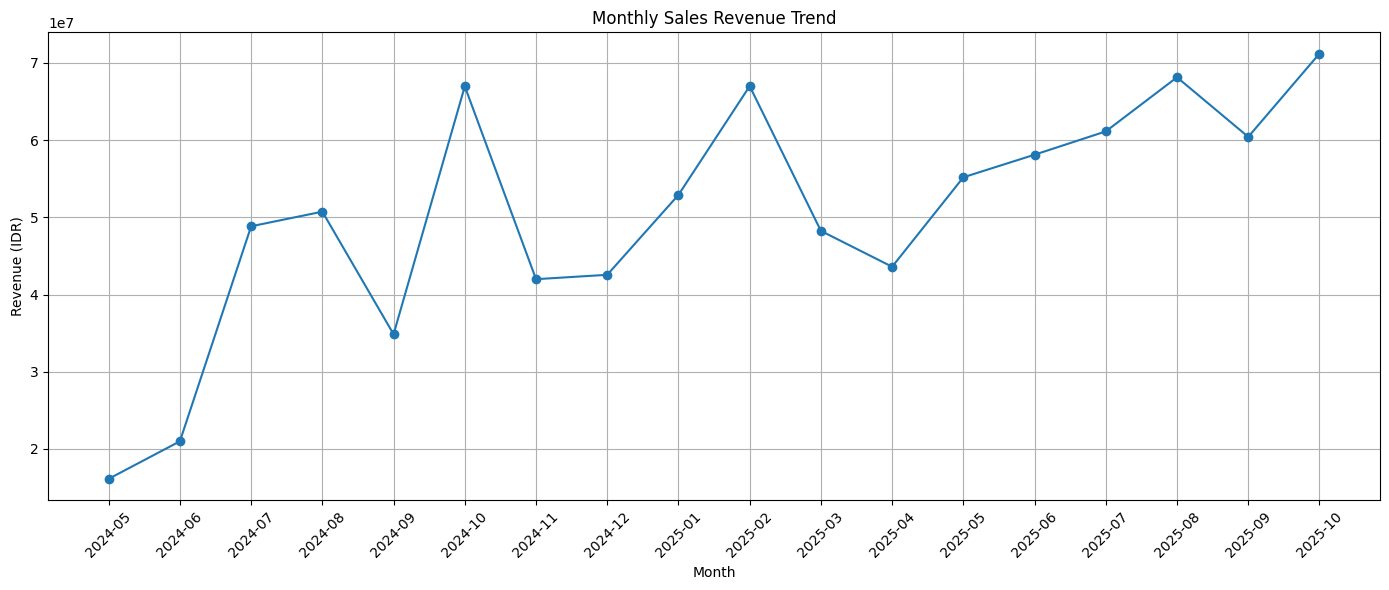

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["month"],
    monthly_sales["item_price_amount"],
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (IDR)")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
product_sales = (
    df.groupby("item_name")["item_price_amount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(product_sales.head(10))

                     item_name  item_price_amount
0           BANNER OUTDOOR 280        248318920.0
1                 STIKER VINYL         61277505.0
2        BANNER FLEXY CINA 280         50104685.0
3       BANNER FLEXY KOREA 440         45746975.0
4                  JASA DESAIN         22596200.0
5                KARTU ID CARD         22062200.0
6  ROLL UP BANNER FLEXY 60X160         20835000.0
7              STIKER LABEL A3         17418900.0
8        BANNER FLEXY CINA 340         17309000.0
9    LANYARD FULL PRINT 2 SISI         15643800.0


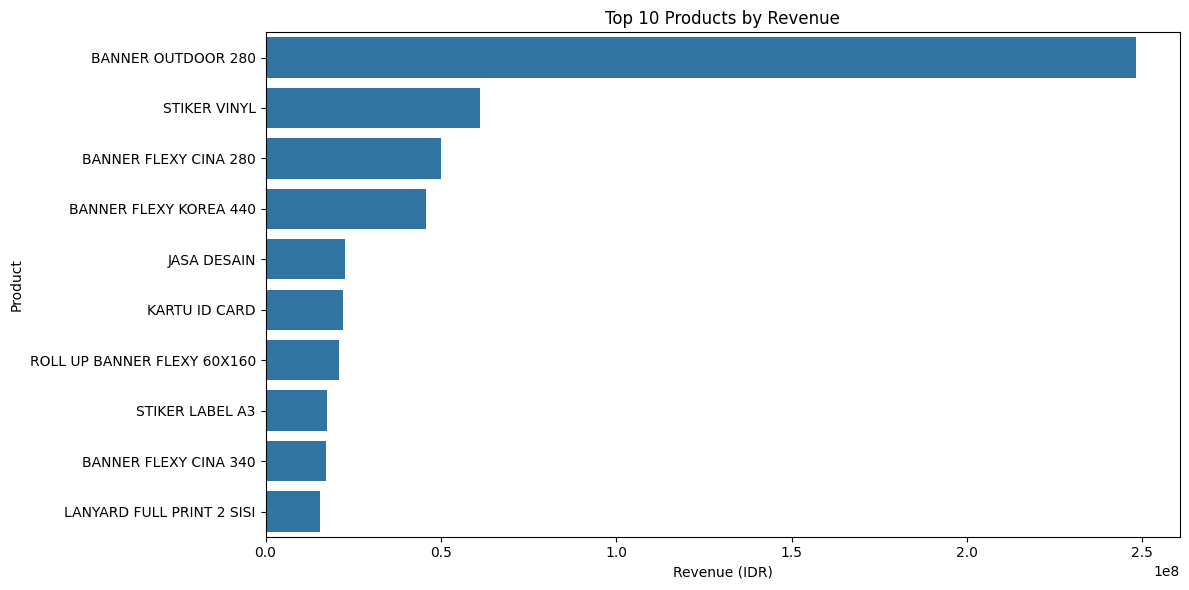

In [ ]:
top_products = product_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="item_price_amount",
    y="item_name"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (IDR)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [ ]:
customer_sales = (
    df.groupby("customer_code")
    .agg(
        total_revenue=("item_price_amount", "sum"),
        total_orders=("invoice_code", "nunique")
    )
    .reset_index()
)

customer_sales = customer_sales.sort_values(
    by="total_revenue",
    ascending=False
)

print(customer_sales.head(10))

    customer_code  total_revenue  total_orders
0           P0008    111979060.0           106
155         P0193     30998320.0            34
183         P0224     28627200.0             6
49          P0070     13150000.0            35
932         P1067     12492000.0             5
341         P0404     11975000.0             2
300         P0359      8940000.0             9
59          P0086      8568050.0            50
33          P0050      8009285.0            55
309         P0368      7279500.0            23


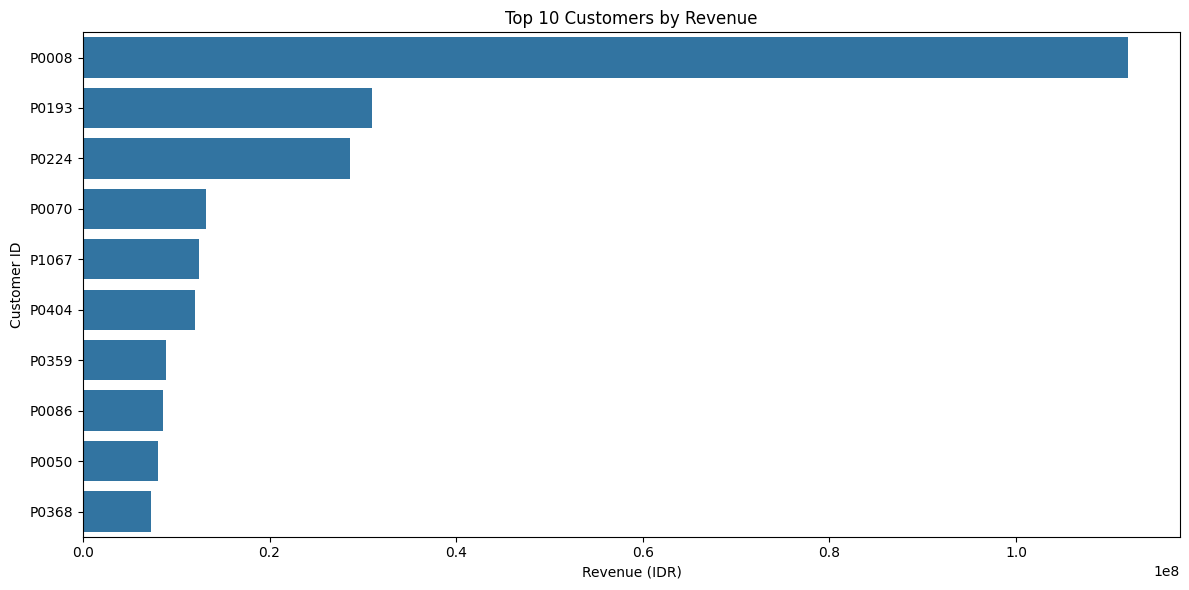

In [ ]:
top_customers = customer_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="total_revenue",
    y="customer_code"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (IDR)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [ ]:
customer_frequency = (
    df.groupby("customer_code")["invoice_code"]
    .nunique()
)

repeat_customers = (
    customer_frequency[customer_frequency >= 2]
)

one_time_customers = (
    customer_frequency[customer_frequency == 1]
)

print("Returning customers:", len(repeat_customers))

print("One-time customers:", len(one_time_customers))

Returning customers: 822
One-time customers: 1372


In [ ]:
total_customer_count = len(customer_frequency)

repeat_percentage = (
    len(repeat_customers) /
    total_customer_count
) * 100

one_time_percentage = (
    len(one_time_customers) /
    total_customer_count
) * 100

print("Returning customer %:", repeat_percentage)

print("One-time customer %:", one_time_percentage)

Returning customer %: 37.46581586144029
One-time customer %: 62.53418413855971


In [ ]:
monthly_sales.to_csv(
    "monthly_sales_analysis.csv",
    index=False
)

product_sales.to_csv(
    "product_sales_analysis.csv",
    index=False
)

customer_sales.to_csv(
    "customer_sales_analysis.csv",
    index=False
)

print("EDA analysis files saved successfully!")

EDA analysis files saved successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_cleaned.csv")

df["transaction_at"] = pd.to_datetime(
    df["transaction_at"]
)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(8617, 9)


In [ ]:
total_revenue = df["item_price_amount"].sum()

total_orders = df["invoice_code"].nunique()

total_customers = df["customer_code"].nunique()

total_products = df["item_name"].nunique()

average_order_value = total_revenue / total_orders

print("TOTAL REVENUE:", total_revenue)
print("TOTAL ORDERS:", total_orders)
print("TOTAL CUSTOMERS:", total_customers)
print("TOTAL PRODUCTS:", total_products)
print("AVERAGE ORDER VALUE:", average_order_value)

TOTAL REVENUE: 909042082.1
TOTAL ORDERS: 5547
TOTAL CUSTOMERS: 2194
TOTAL PRODUCTS: 273
AVERAGE ORDER VALUE: 163879.9499008473


In [ ]:
df["month"] = (
    df["transaction_at"]
    .dt.to_period("M")
    .astype(str)
)

monthly_sales = (
    df.groupby("month")["item_price_amount"]
    .sum()
    .reset_index()
)

print(monthly_sales)

      month  item_price_amount
0   2024-05         16128500.0
1   2024-06         20988860.0
2   2024-07         48842535.0
3   2024-08         50736085.0
4   2024-09         34857670.0
5   2024-10         66972510.0
6   2024-11         41990520.0
7   2024-12         42556197.0
8   2025-01         52908591.0
9   2025-02         66998039.0
10  2025-03         48244610.0
11  2025-04         43599885.1
12  2025-05         55188655.0
13  2025-06         58115240.0
14  2025-07         61132650.0
15  2025-08         68143950.0
16  2025-09         60424605.0
17  2025-10         71212980.0


In [ ]:
# Import required libraries
import pandas as pd
import sqlite3

# Load the cleaned CSV file
df = pd.read_csv("sales_cleaned.csv")

# Create a SQLite database connection
conn = sqlite3.connect("sales_analysis.db")

# Transfer the dataset into an SQL table
df.to_sql("sales", conn, if_exists="replace", index=False)

print("Dataset successfully loaded into SQL!")

Dataset successfully loaded into SQL!


In [ ]:
query = """
SELECT *
FROM sales
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)
result

,invoice_code,customer_code,item_name,item_quantity,item_price,item_price_amount,transaction_at,extra_flag,zero_price_flag
0,SI24100331,P0535,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2024-10-27 11:29:00,None,0
1,SI25050137,P0126,STEMPEL D40,1.0,65000.0,65000.0,2025-05-10 11:41:00,None,0
2,SI25030102,P0126,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2025-03-10 09:58:00,None,0
3,SI25010344,P0126,BANNER OUTDOOR 280,4.4,20000.0,88000.0,2025-01-30 17:46:00,None,0
4,SI24120053,P0126,CUTTING STIKER (SCOTLET),713.0,65.0,46345.0,2024-12-06 09:53:00,None,0


In [ ]:
pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM sales;",
    conn
)

,total_records
0,8617


In [ ]:
query = """
SELECT
    customer_code,
    item_name,
    item_price_amount
FROM sales
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,customer_code,item_name,item_price_amount
0,P0535,BANNER OUTDOOR 280,60000.0
1,P0126,STEMPEL D40,65000.0
2,P0126,BANNER OUTDOOR 280,60000.0
3,P0126,BANNER OUTDOOR 280,88000.0
4,P0126,CUTTING STIKER (SCOTLET),46345.0
5,P0126,BANNER OUTDOOR 280,30000.0
6,P0126,CUTTING STIKER (SCOTLET),43355.0
7,P0126,CUTTING STIKER (SCOTLET),36400.0
8,P0126,BANNER FLEXY CINA 280,486200.0
9,P0126,BANNER FLEXY CINA 280,162500.0


In [ ]:
query = """
SELECT *
FROM sales
WHERE item_price_amount > 100000
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,invoice_code,customer_code,item_name,item_quantity,item_price,item_price_amount,transaction_at,extra_flag,zero_price_flag
0,SI24070048,P0126,BANNER FLEXY CINA 280,28.60,17000.0,486200.0,2024-07-04 17:02:00,None,0
1,SI24060351,P0126,BANNER FLEXY CINA 280,6.25,26000.0,162500.0,2024-06-28 18:47:00,None,0
2,SI24100288,P0506,BANNER OUTDOOR 280,6.00,20000.0,120000.0,2024-10-23 14:06:00,None,0
3,SI25080175,P2038,BANNER FLEXY KOREA 440,2.00,55000.0,110000.0,2025-08-09 13:30:00,None,0
4,SI25080175,P2038,KARTU NAMA 1 SISI,3.00,45000.0,135000.0,2025-08-09 13:30:00,None,0
5,SI25080394,P2146,BANNER OUTDOOR 280,6.00,20000.0,120000.0,2025-08-22 16:43:00,None,0
6,SI25050423,T-R,KAOS DTF 24S LENGAN PENDEK S/M/L/XL,2.00,85000.0,170000.0,2025-05-31 20:39:00,None,0
7,SI25050375,T-R,KAOS DTF 24S LENGAN PENDEK S/M/L/XL,5.00,85000.0,425000.0,2025-05-28 14:45:00,None,0
8,SI25060155,P1701,BROSUR GLOSSY 1 SISI A5 1 RIM,2.00,345000.0,690000.0,2025-06-13 09:46:00,None,0
9,SI25020164,P1001,BANNER OUTDOOR 280,8.40,20000.0,168000.0,2025-02-12 10:36:00,None,0


In [ ]:
query = """
SELECT *
FROM sales
WHERE item_name = 'BANNER OUTDOOR 280'
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,invoice_code,customer_code,item_name,item_quantity,item_price,item_price_amount,transaction_at,extra_flag,zero_price_flag
0,SI24100331,P0535,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2024-10-27 11:29:00,None,0
1,SI25030102,P0126,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2025-03-10 09:58:00,None,0
2,SI25010344,P0126,BANNER OUTDOOR 280,4.4,20000.0,88000.0,2025-01-30 17:46:00,None,0
3,SI24100064,P0126,BANNER OUTDOOR 280,1.5,20000.0,30000.0,2024-10-05 15:32:00,None,0
4,SI25020239,P1122,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2025-02-17 10:38:00,None,0
5,SI24100326,P0506,BANNER OUTDOOR 280,1.0,20000.0,20000.0,2024-10-26 20:12:00,None,0
6,SI24100314,P0506,BANNER OUTDOOR 280,2.0,20000.0,40000.0,2024-10-25 15:31:00,None,0
7,SI24100288,P0506,BANNER OUTDOOR 280,6.0,20000.0,120000.0,2024-10-23 14:06:00,None,0
8,SI25070128,P1822,BANNER OUTDOOR 280,3.0,20000.0,60000.0,2025-07-11 18:00:00,None,0
9,SI25080394,P2146,BANNER OUTDOOR 280,6.0,20000.0,120000.0,2025-08-22 16:43:00,None,0


In [ ]:
query = """
SELECT
    item_name,
    item_price_amount
FROM sales
ORDER BY item_price_amount DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,item_name,item_price_amount
0,STIKER VINYL,16500000.0
1,LANYARD FULL PRINT 2 SISI,11200000.0
2,BILLBOARD PAPAN NAMA,10000000.0
3,SATIN CLOTH BANNER,8250000.0
4,STIKER CROMO F4,6960000.0
5,ROLL UP BANNER FLEXY 80X200,6815000.0
6,ROLL UP BANNER FLEXY 60X160,6615000.0
7,SATIN CLOTH BANNER OUTDOOR,6600000.0
8,TALI LANYARD,6400000.0
9,BANNER FLEXY CINA 340,6300000.0


In [ ]:
query = """
SELECT
    item_name,
    SUM(item_price_amount) AS total_revenue
FROM sales
GROUP BY item_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,item_name,total_revenue
0,BANNER OUTDOOR 280,248318920.0
1,STIKER VINYL,61277505.0
2,BANNER FLEXY CINA 280,50104685.0
3,BANNER FLEXY KOREA 440,45746975.0
4,JASA DESAIN,22596200.0
5,KARTU ID CARD,22062200.0
6,ROLL UP BANNER FLEXY 60X160,20835000.0
7,STIKER LABEL A3,17418900.0
8,BANNER FLEXY CINA 340,17309000.0
9,LANYARD FULL PRINT 2 SISI,15643800.0


In [ ]:
query = """
SELECT
    customer_code,
    SUM(item_price_amount) AS total_revenue
FROM sales
GROUP BY customer_code
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,customer_code,total_revenue
0,P0008,111979060.0
1,P0193,30998320.0
2,P0224,28627200.0
3,P0070,13150000.0
4,P1067,12492000.0
5,P0404,11975000.0
6,P0359,8940000.0
7,P0086,8568050.0
8,P0050,8009285.0
9,P0368,7279500.0


In [ ]:
queries = {
    "Monthly Revenue": """
        SELECT
            strftime('%Y-%m', transaction_at) AS month,
            SUM(item_price_amount) AS revenue
        FROM sales
        GROUP BY month
        ORDER BY month;
    """,

    "Top 10 Products": """
        SELECT
            item_name,
            SUM(item_price_amount) AS revenue
        FROM sales
        GROUP BY item_name
        ORDER BY revenue DESC
        LIMIT 10;
    """,

    "Top 10 Customers": """
        SELECT
            customer_code,
            SUM(item_price_amount) AS revenue,
            COUNT(DISTINCT invoice_code) AS orders
        FROM sales
        GROUP BY customer_code
        ORDER BY revenue DESC
        LIMIT 10;
    """,

    "Average Order Value": """
        SELECT
            SUM(item_price_amount) /
            COUNT(DISTINCT invoice_code) AS average_order_value
        FROM sales;
    """,

    "Customer Purchase Frequency": """
        SELECT
            CASE
                WHEN order_count = 1 THEN 'One-time'
                ELSE 'Repeat'
            END AS customer_type,
            COUNT(*) AS customer_count
        FROM (
            SELECT
                customer_code,
                COUNT(DISTINCT invoice_code) AS order_count
            FROM sales
            GROUP BY customer_code
        )
        GROUP BY customer_type;
    """
}

for report_name, query in queries.items():
    print("\\n==========", report_name, "==========")
    display(pd.read_sql_query(query, conn))

\n========== Monthly Revenue ==========


,month,revenue
0,2024-05,16128500.0
1,2024-06,20988860.0
2,2024-07,48842535.0
3,2024-08,50736085.0
4,2024-09,34857670.0
5,2024-10,66972510.0
6,2024-11,41990520.0
7,2024-12,42556197.0
8,2025-01,52908591.0
9,2025-02,66998039.0


\n========== Top 10 Products ==========


,item_name,revenue
0,BANNER OUTDOOR 280,248318920.0
1,STIKER VINYL,61277505.0
2,BANNER FLEXY CINA 280,50104685.0
3,BANNER FLEXY KOREA 440,45746975.0
4,JASA DESAIN,22596200.0
5,KARTU ID CARD,22062200.0
6,ROLL UP BANNER FLEXY 60X160,20835000.0
7,STIKER LABEL A3,17418900.0
8,BANNER FLEXY CINA 340,17309000.0
9,LANYARD FULL PRINT 2 SISI,15643800.0


\n========== Top 10 Customers ==========


,customer_code,revenue,orders
0,P0008,111979060.0,106
1,P0193,30998320.0,34
2,P0224,28627200.0,6
3,P0070,13150000.0,35
4,P1067,12492000.0,5
5,P0404,11975000.0,2
6,P0359,8940000.0,9
7,P0086,8568050.0,50
8,P0050,8009285.0,55
9,P0368,7279500.0,23


\n========== Average Order Value ==========


,average_order_value
0,163879.949901


\n========== Customer Purchase Frequency ==========


,customer_type,customer_count
0,One-time,1372
1,Repeat,822


In [ ]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("sales_cleaned.csv")

# Convert transaction date into datetime format
df["transaction_at"] = pd.to_datetime(df["transaction_at"])

# Reference date: one day after the latest transaction
reference_date = df["transaction_at"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df.groupby("customer_code").agg(
    recency=("transaction_at", lambda x: (reference_date - x.max()).days),
    frequency=("invoice_code", "nunique"),
    monetary=("item_price_amount", "sum")
).reset_index()

# Calculate scores from 1 to 5
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_score"] = (
    rfm["R_score"] +
    rfm["F_score"] +
    rfm["M_score"]
)

# Assign customer segments
def segment_customer(row):
    if row["RFM_score"] >= 13:
        return "High Value"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"
    elif row["R_score"] >= 4 and row["F_score"] >= 3:
        return "Loyal Customers"
    elif row["F_score"] <= 2 and row["R_score"] <= 2:
        return "Needs Attention"
    else:
        return "Regular Customers"

rfm["customer_segment"] = rfm.apply(segment_customer, axis=1)

# Display results
rfm.head(10)

,customer_code,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,customer_segment
0,P0008,1,106,111979060.0,5,5,5,15,High Value
1,P0010,110,4,125000.0,4,5,3,12,Loyal Customers
2,P0011,547,1,825000.0,1,1,5,7,Needs Attention
3,P0012,133,7,233000.0,3,5,4,12,Regular Customers
4,P0016,113,26,2753630.0,4,5,5,14,High Value
5,P0017,262,2,542950.0,2,4,5,11,At Risk
6,P0018,508,5,135000.0,1,5,3,9,At Risk
7,P0019,49,13,5149500.0,5,5,5,15,High Value
8,P0020,546,1,285000.0,1,1,4,6,Needs Attention
9,P0021,294,17,2782000.0,2,5,5,12,At Risk


In [ ]:
segment_summary = rfm.groupby("customer_segment").agg(
    customer_count=("customer_code", "count"),
    total_revenue=("monetary", "sum")
).reset_index()

segment_summary["revenue_percentage"] = (
    segment_summary["total_revenue"] /
    segment_summary["total_revenue"].sum() * 100
)

segment_summary

,customer_segment,customer_count,total_revenue,revenue_percentage
0,At Risk,219,99944159.0,10.994448
1,High Value,398,600136851.1,66.018599
2,Loyal Customers,522,53498350.0,5.885135
3,Needs Attention,659,91440962.0,10.059046
4,Regular Customers,396,64021760.0,7.042772


In [ ]:
rfm.to_csv("customer_rfm_analysis.csv", index=False)
segment_summary.to_csv("customer_segment_summary.csv", index=False)

print("RFM analysis completed and exported!")

RFM analysis completed and exported!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("sales_cleaned.csv")
df["transaction_at"] = pd.to_datetime(df["transaction_at"])

monthly_sales = (
    df.set_index("transaction_at")
      .resample("MS")["item_price_amount"]
      .sum()
      .reset_index()
)

monthly_sales.columns = ["month", "revenue"]

monthly_sales

,month,revenue
0,2024-05-01,16128500.0
1,2024-06-01,20988860.0
2,2024-07-01,48842535.0
3,2024-08-01,50736085.0
4,2024-09-01,34857670.0
5,2024-10-01,66972510.0
6,2024-11-01,41990520.0
7,2024-12-01,42556197.0
8,2025-01-01,52908591.0
9,2025-02-01,66998039.0


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a time index
monthly_sales["time"] = np.arange(len(monthly_sales))

# Use the first 15 months for training
train = monthly_sales.iloc[:-3]
test = monthly_sales.iloc[-3:]

X_train = train[["time"]]
y_train = train["revenue"]

X_test = test[["time"]]
y_test = test["revenue"]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the final 3 months
predictions = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 4205467.94
RMSE: 4396746.16


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a time index
monthly_sales["time"] = np.arange(len(monthly_sales))

# Use the first 15 months for training
train = monthly_sales.iloc[:-3]
test = monthly_sales.iloc[-3:]

X_train = train[["time"]]
y_train = train["revenue"]

X_test = test[["time"]]
y_test = test["revenue"]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict the final 3 months
predictions = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 4205467.94
RMSE: 4396746.16


In [ ]:
future_time = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 3
).reshape(-1, 1)

future_predictions = model.predict(future_time)

future_dates = pd.date_range(
    start=monthly_sales["month"].max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

forecast = pd.DataFrame({
    "month": future_dates,
    "predicted_revenue": future_predictions
})

forecast

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,month,predicted_revenue
0,2025-11-01,7.054523e+07
1,2025-12-01,7.265988e+07
2,2026-01-01,7.477454e+07


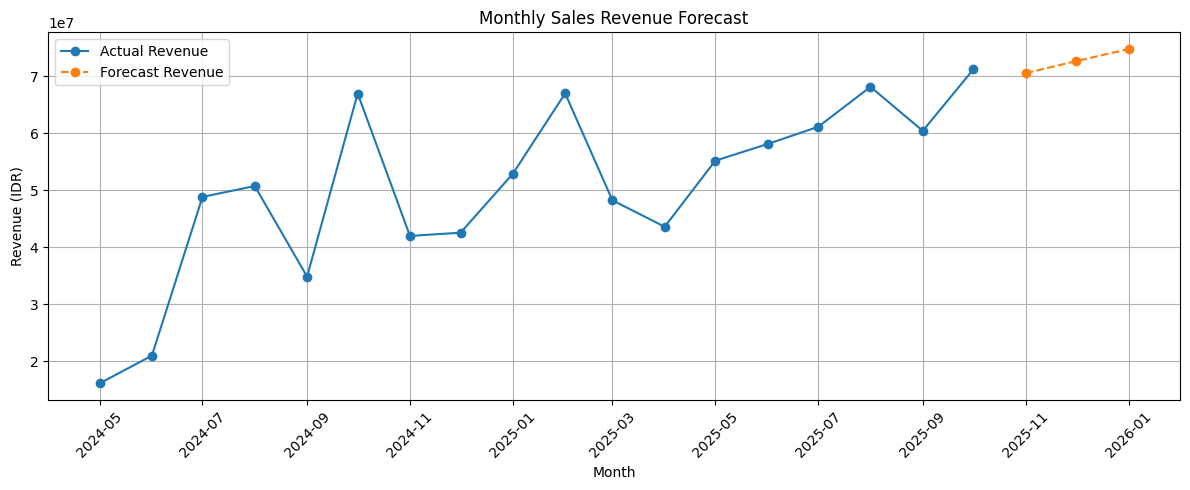

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    forecast["month"],
    forecast["predicted_revenue"],
    marker="o",
    linestyle="--",
    label="Forecast Revenue"
)

plt.title("Monthly Sales Revenue Forecast")
plt.xlabel("Month")
plt.ylabel("Revenue (IDR)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
forecast.to_csv("sales_forecast.csv", index=False)

print("Sales forecasting completed!")

Sales forecasting completed!


In [1]:
import pandas as pd

df = pd.read_csv("sales_cleaned.csv")

df["transaction_at"] = pd.to_datetime(df["transaction_at"])

# Reference date
reference_date = df["transaction_at"].max() + pd.Timedelta(days=1)

# Calculate customer RFM
rfm = df.groupby("customer_code").agg(
    Recency=("transaction_at", lambda x: (reference_date - x.max()).days),
    Frequency=("invoice_code", "nunique"),
    Monetary=("item_price_amount", "sum")
).reset_index()

rfm.head()

FileNotFoundError: [Errno 2] No such file or directory: 'sales_cleaned.csv'

In [2]:
from google.colab import files
uploaded = files.upload()

Saving sales_cleaned.csv to sales_cleaned.csv


In [3]:
import pandas as pd

df = pd.read_csv("sales_cleaned.csv")

df["transaction_at"] = pd.to_datetime(df["transaction_at"])

# Reference date
reference_date = df["transaction_at"].max() + pd.Timedelta(days=1)

# Calculate customer RFM
rfm = df.groupby("customer_code").agg(
    Recency=("transaction_at", lambda x: (reference_date - x.max()).days),
    Frequency=("invoice_code", "nunique"),
    Monetary=("item_price_amount", "sum")
).reset_index()

rfm.head()

,customer_code,Recency,Frequency,Monetary
0,P0008,1,106,111979060.0
1,P0010,110,4,125000.0
2,P0011,547,1,825000.0
3,P0012,133,7,233000.0
4,P0016,113,26,2753630.0


In [4]:
rfm.shape

(2194, 4)

In [5]:
# Assign scores from 1 to 5

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head(10)

,customer_code,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,P0008,1,106,111979060.0,5,5,5,555
1,P0010,110,4,125000.0,4,5,3,453
2,P0011,547,1,825000.0,1,1,5,115
3,P0012,133,7,233000.0,3,5,4,354
4,P0016,113,26,2753630.0,4,5,5,455
5,P0017,262,2,542950.0,2,4,5,245
6,P0018,508,5,135000.0,1,5,3,153
7,P0019,49,13,5149500.0,5,5,5,555
8,P0020,546,1,285000.0,1,1,4,114
9,P0021,294,17,2782000.0,2,5,5,255


In [6]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    else:
        return "Regular Customers"

rfm["Customer_Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head(10)

,customer_code,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,P0008,1,106,111979060.0,5,5,5,555,Champions
1,P0010,110,4,125000.0,4,5,3,453,Loyal Customers
2,P0011,547,1,825000.0,1,1,5,115,Regular Customers
3,P0012,133,7,233000.0,3,5,4,354,Loyal Customers
4,P0016,113,26,2753630.0,4,5,5,455,Champions
5,P0017,262,2,542950.0,2,4,5,245,At Risk
6,P0018,508,5,135000.0,1,5,3,153,At Risk
7,P0019,49,13,5149500.0,5,5,5,555,Champions
8,P0020,546,1,285000.0,1,1,4,114,Regular Customers
9,P0021,294,17,2782000.0,2,5,5,255,At Risk


In [7]:
segment_summary = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["Customer Segment", "Customer Count"]

segment_summary

,Customer Segment,Customer Count
0,Regular Customers,1311
1,Champions,365
2,Loyal Customers,294
3,At Risk,219
4,New Customers,5


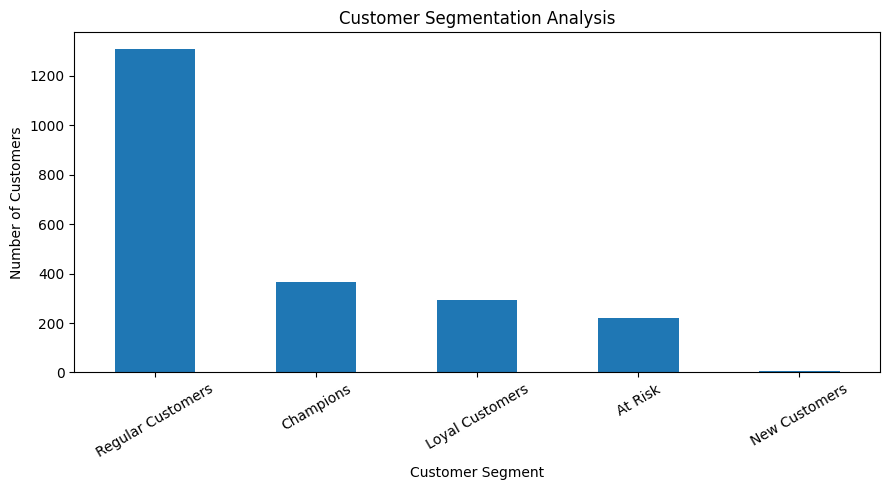

In [8]:
import matplotlib.pyplot as plt

segment_counts = rfm["Customer_Segment"].value_counts()

plt.figure(figsize=(9, 5))
segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [9]:
# Save customer-level RFM analysis
rfm.to_csv("customer_rfm_segments.csv", index=False)

# Save segment summary
segment_summary.to_csv("customer_segment_summary.csv", index=False)

from google.colab import files

files.download("customer_rfm_segments.csv")
files.download("customer_segment_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import pandas as pd

df["transaction_at"] = pd.to_datetime(df["transaction_at"])

monthly_sales = (
    df.set_index("transaction_at")
      .resample("MS")["item_price_amount"]
      .sum()
      .reset_index()
)

monthly_sales.columns = ["Month", "Actual_Revenue"]

display(monthly_sales)

,Month,Actual_Revenue
0,2024-05-01,16128500.0
1,2024-06-01,20988860.0
2,2024-07-01,48842535.0
3,2024-08-01,50736085.0
4,2024-09-01,34857670.0
5,2024-10-01,66972510.0
6,2024-11-01,41990520.0
7,2024-12-01,42556197.0
8,2025-01-01,52908591.0
9,2025-02-01,66998039.0


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import numpy as np

# Create time index
monthly_sales["Month_Index"] = range(len(monthly_sales))

# Split: first 15 months for training, last 3 for testing
X = monthly_sales[["Month_Index"]]
y = monthly_sales["Actual_Revenue"]

X_train, X_test = X.iloc[:15], X.iloc[15:]
y_train, y_test = y.iloc[:15], y.iloc[15:]

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Test predictions
test_predictions = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, test_predictions)
mape = mean_absolute_percentage_error(y_test, test_predictions) * 100

print("MAE:", round(mae, 2))
print("MAPE:", round(mape, 2), "%")

# Train final model using all 18 months
model.fit(X, y)

# Forecast next 3 months
future_index = np.array([[18], [19], [20]])
forecast = model.predict(future_index)

forecast_df = pd.DataFrame({
    "Month": pd.date_range(
        start=monthly_sales["Month"].max() + pd.offsets.MonthBegin(1),
        periods=3,
        freq="MS"
    ),
    "Forecast_Revenue": forecast
})

display(forecast_df)

MAE: 4205467.94
MAPE: 6.48 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Month,Forecast_Revenue
0,2025-11-01,7.069141e+07
1,2025-12-01,7.281658e+07
2,2026-01-01,7.494174e+07


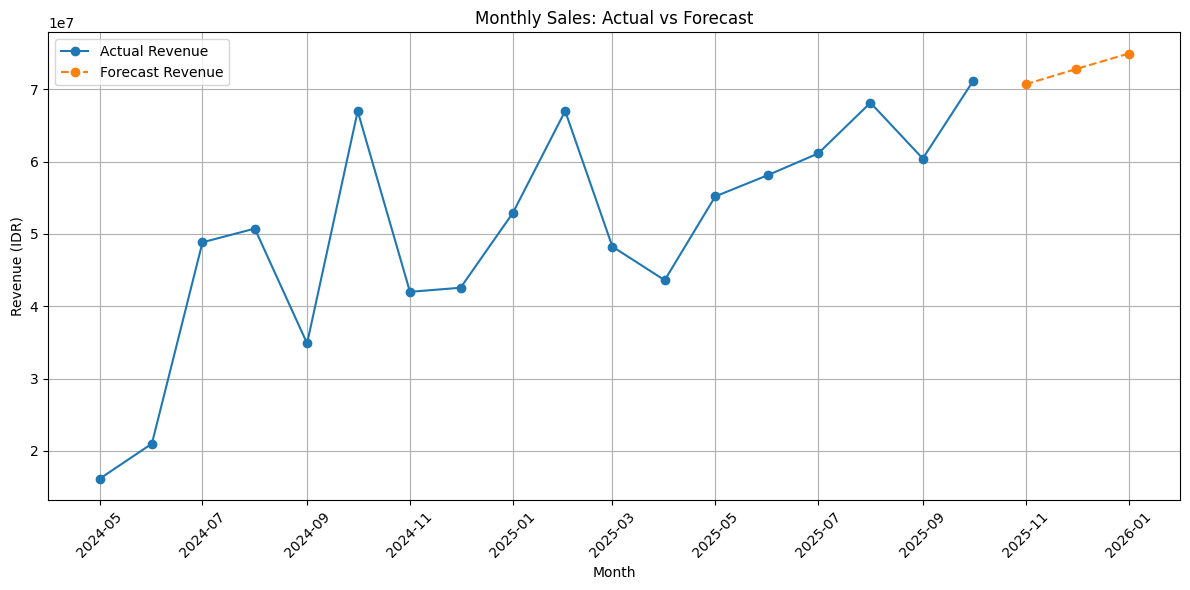

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Historical sales
plt.plot(
    monthly_sales["Month"],
    monthly_sales["Actual_Revenue"],
    marker="o",
    label="Actual Revenue"
)

# Forecasted sales
plt.plot(
    forecast_df["Month"],
    forecast_df["Forecast_Revenue"],
    marker="o",
    linestyle="--",
    label="Forecast Revenue"
)

plt.title("Monthly Sales: Actual vs Forecast")
plt.xlabel("Month")
plt.ylabel("Revenue (IDR)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Combine historical and forecast data

actual_data = monthly_sales[["Month", "Actual_Revenue"]].copy()
actual_data["Forecast_Revenue"] = None

future_data = forecast_df.copy()
future_data["Actual_Revenue"] = None

final_forecast = pd.concat(
    [actual_data, future_data],
    ignore_index=True
)

# Export CSV
final_forecast.to_csv("sales_forecast.csv", index=False)

print("Forecast file created successfully!")
display(final_forecast.tail(6))

Forecast file created successfully!


/tmp/ipykernel_2005/521801186.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_forecast = pd.concat(


,Month,Actual_Revenue,Forecast_Revenue
15,2025-08-01,68143950.0,NaN
16,2025-09-01,60424605.0,NaN
17,2025-10-01,71212980.0,NaN
18,2025-11-01,NaN,7.069141e+07
19,2025-12-01,NaN,7.281658e+07
20,2026-01-01,NaN,7.494174e+07


In [15]:
from google.colab import files
files.download("sales_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
query = """
SELECT
    month,
    revenue,
    LAG(revenue) OVER (ORDER BY month) AS previous_month_revenue,
    ROUND(
        (revenue - LAG(revenue) OVER (ORDER BY month))
        * 100.0 / LAG(revenue) OVER (ORDER BY month), 2
    ) AS growth_percentage
FROM (
    SELECT
        strftime('%Y-%m', transaction_at) AS month,
        SUM(item_price_amount) AS revenue
    FROM sales
    GROUP BY month
)
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)
display(result)

NameError: name 'conn' is not defined

In [19]:
import pandas as pd
import sqlite3

df = pd.read_csv("sales_cleaned.csv")

conn = sqlite3.connect("sales_analysis.db")

df.to_sql("sales", conn, if_exists="replace", index=False)

print("Database connected successfully!")

Database connected successfully!


In [20]:
query = """
SELECT
    month,
    revenue,
    LAG(revenue) OVER (ORDER BY month) AS previous_month_revenue,
    ROUND(
        (revenue - LAG(revenue) OVER (ORDER BY month))
        * 100.0 / LAG(revenue) OVER (ORDER BY month), 2
    ) AS growth_percentage
FROM (
    SELECT
        strftime('%Y-%m', transaction_at) AS month,
        SUM(item_price_amount) AS revenue
    FROM sales
    GROUP BY month
)
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)
display(result)

,month,revenue,previous_month_revenue,growth_percentage
0,2024-05,16128500.0,NaN,NaN
1,2024-06,20988860.0,16128500.0,30.14
2,2024-07,48842535.0,20988860.0,132.71
3,2024-08,50736085.0,48842535.0,3.88
4,2024-09,34857670.0,50736085.0,-31.30
5,2024-10,66972510.0,34857670.0,92.13
6,2024-11,41990520.0,66972510.0,-37.30
7,2024-12,42556197.0,41990520.0,1.35
8,2025-01,52908591.0,42556197.0,24.33
9,2025-02,66998039.0,52908591.0,26.63


In [21]:
query = """
SELECT
    item_name,
    ROUND(SUM(item_price_amount), 2) AS total_revenue,
    RANK() OVER (
        ORDER BY SUM(item_price_amount) DESC
    ) AS revenue_rank
FROM sales
GROUP BY item_name
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,item_name,total_revenue,revenue_rank
0,BANNER OUTDOOR 280,248318920.0,1
1,STIKER VINYL,61277505.0,2
2,BANNER FLEXY CINA 280,50104685.0,3
3,BANNER FLEXY KOREA 440,45746975.0,4
4,JASA DESAIN,22596200.0,5
5,KARTU ID CARD,22062200.0,6
6,ROLL UP BANNER FLEXY 60X160,20835000.0,7
7,STIKER LABEL A3,17418900.0,8
8,BANNER FLEXY CINA 340,17309000.0,9
9,LANYARD FULL PRINT 2 SISI,15643800.0,10


In [22]:
query = """
WITH customer_orders AS (
    SELECT
        customer_code,
        COUNT(DISTINCT invoice_code) AS total_orders,
        SUM(item_price_amount) AS total_revenue
    FROM sales
    GROUP BY customer_code
)
SELECT
    CASE
        WHEN total_orders = 1 THEN 'One-Time Customer'
        ELSE 'Repeat Customer'
    END AS customer_type,
    COUNT(*) AS customer_count,
    ROUND(SUM(total_revenue), 2) AS total_revenue
FROM customer_orders
GROUP BY customer_type
ORDER BY customer_count DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,customer_type,customer_count,total_revenue
0,One-Time Customer,1372,181387542.0
1,Repeat Customer,822,727654540.1


In [23]:
query = """
WITH monthly_sales AS (
    SELECT
        strftime('%Y-%m', transaction_at) AS month,
        SUM(item_price_amount) AS revenue
    FROM sales
    GROUP BY month
),
growth AS (
    SELECT
        month,
        revenue,
        LAG(revenue) OVER (ORDER BY month) AS previous_month_revenue
    FROM monthly_sales
)
SELECT
    month,
    ROUND(revenue, 2) AS revenue,
    ROUND(previous_month_revenue, 2) AS previous_month_revenue,
    ROUND(
        (revenue - previous_month_revenue)
        * 100.0 / previous_month_revenue, 2
    ) AS growth_percentage
FROM growth
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)
display(result)

,month,revenue,previous_month_revenue,growth_percentage
0,2024-05,16128500.0,NaN,NaN
1,2024-06,20988860.0,16128500.0,30.14
2,2024-07,48842535.0,20988860.0,132.71
3,2024-08,50736085.0,48842535.0,3.88
4,2024-09,34857670.0,50736085.0,-31.30
5,2024-10,66972510.0,34857670.0,92.13
6,2024-11,41990520.0,66972510.0,-37.30
7,2024-12,42556197.0,41990520.0,1.35
8,2025-01,52908591.0,42556197.0,24.33
9,2025-02,66998039.0,52908591.0,26.63


In [24]:
query = """
SELECT
    customer_code,
    COUNT(DISTINCT invoice_code) AS total_orders,
    ROUND(SUM(item_price_amount), 2) AS lifetime_revenue,
    ROUND(AVG(item_price_amount), 2) AS avg_item_revenue
FROM sales
GROUP BY customer_code
ORDER BY lifetime_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)

,customer_code,total_orders,lifetime_revenue,avg_item_revenue
0,P0008,106,111979060.0,794177.73
1,P0193,34,30998320.0,659538.72
2,P0224,6,28627200.0,2602472.73
3,P0070,35,13150000.0,152906.98
4,P1067,5,12492000.0,1561500.00
5,P0404,2,11975000.0,1710714.29
6,P0359,9,8940000.0,687692.31
7,P0086,50,8568050.0,108456.33
8,P0050,55,8009285.0,100116.06
9,P0368,23,7279500.0,220590.91


In [25]:
query = """
WITH monthly_sales AS (
    SELECT
        strftime('%Y-%m', transaction_at) AS month,
        SUM(item_price_amount) AS monthly_revenue
    FROM sales
    GROUP BY month
)
SELECT
    month,
    ROUND(monthly_revenue, 2) AS monthly_revenue,
    ROUND(
        SUM(monthly_revenue) OVER (
            ORDER BY month
        ), 2
    ) AS cumulative_revenue
FROM monthly_sales
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)
display(result)

,month,monthly_revenue,cumulative_revenue
0,2024-05,16128500.0,16128500.0
1,2024-06,20988860.0,37117360.0
2,2024-07,48842535.0,85959895.0
3,2024-08,50736085.0,136695980.0
4,2024-09,34857670.0,171553650.0
5,2024-10,66972510.0,238526160.0
6,2024-11,41990520.0,280516680.0
7,2024-12,42556197.0,323072877.0
8,2025-01,52908591.0,375981468.0
9,2025-02,66998039.0,442979507.0


In [26]:
query = """
SELECT
    customer_code,
    COUNT(DISTINCT invoice_code) AS total_orders,
    ROUND(SUM(item_price_amount), 2) AS total_revenue
FROM sales
GROUP BY customer_code
ORDER BY total_orders DESC
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)
display(result)

,customer_code,total_orders,total_revenue
0,P0008,106,111979060.0
1,P0116,68,1209000.0
2,P0387,65,3415340.0
3,P0043,61,6750000.0
4,P0050,55,8009285.0


In [27]:
print("SALES ANALYTICS PROJECT - SQL REPORTS")
print("------------------------------------")
print("1. Monthly Revenue Analysis")
print("2. Top 10 Products by Revenue")
print("3. Top 10 Customers by Revenue")
print("4. Average Order Value")
print("5. Customer Purchase Frequency")
print("6. Monthly Revenue Growth")
print("7. Revenue Ranking")
print("8. Repeat vs One-Time Customers")
print("9. Customer Lifetime Revenue")
print("10. Cumulative Monthly Revenue")
print("11. Top 5 Customers by Purchase Frequency")

SALES ANALYTICS PROJECT - SQL REPORTS
------------------------------------
1. Monthly Revenue Analysis
2. Top 10 Products by Revenue
3. Top 10 Customers by Revenue
4. Average Order Value
5. Customer Purchase Frequency
6. Monthly Revenue Growth
7. Revenue Ranking
8. Repeat vs One-Time Customers
9. Customer Lifetime Revenue
10. Cumulative Monthly Revenue
11. Top 5 Customers by Purchase Frequency


In [28]:
sql_content = """
-- SALES PERFORMANCE & CUSTOMER INSIGHTS PROJECT
-- SQL Business Analysis Reports

-- 1. Monthly Revenue
SELECT strftime('%Y-%m', transaction_at) AS month,
       SUM(item_price_amount) AS revenue
FROM sales
GROUP BY month
ORDER BY month;

-- 2. Top 10 Products by Revenue
SELECT item_name, SUM(item_price_amount) AS total_revenue
FROM sales
GROUP BY item_name
ORDER BY total_revenue DESC
LIMIT 10;

-- 3. Top 10 Customers by Revenue
SELECT customer_code, SUM(item_price_amount) AS total_revenue
FROM sales
GROUP BY customer_code
ORDER BY total_revenue DESC
LIMIT 10;

-- 4. Average Order Value
SELECT ROUND(
    SUM(item_price_amount) / COUNT(DISTINCT invoice_code), 2
) AS average_order_value
FROM sales;

-- 5. Customer Purchase Frequency
SELECT customer_code,
       COUNT(DISTINCT invoice_code) AS total_orders
FROM sales
GROUP BY customer_code
ORDER BY total_orders DESC;

-- 6. Monthly Revenue Growth
WITH monthly_sales AS (
    SELECT strftime('%Y-%m', transaction_at) AS month,
           SUM(item_price_amount) AS revenue
    FROM sales
    GROUP BY month
),
growth AS (
    SELECT month, revenue,
           LAG(revenue) OVER (ORDER BY month) AS previous_revenue
    FROM monthly_sales
)
SELECT month, revenue, previous_revenue,
       ROUND((revenue - previous_revenue)
       * 100.0 / previous_revenue, 2) AS growth_percentage
FROM growth
ORDER BY month;

-- 7. Product Revenue Ranking
SELECT item_name,
       SUM(item_price_amount) AS total_revenue,
       RANK() OVER (ORDER BY SUM(item_price_amount) DESC) AS revenue_rank
FROM sales
GROUP BY item_name
ORDER BY total_revenue DESC
LIMIT 10;

-- 8. Repeat vs One-Time Customers
WITH customer_orders AS (
    SELECT customer_code,
           COUNT(DISTINCT invoice_code) AS total_orders,
           SUM(item_price_amount) AS total_revenue
    FROM sales
    GROUP BY customer_code
)
SELECT
    CASE WHEN total_orders = 1
         THEN 'One-Time Customer'
         ELSE 'Repeat Customer'
    END AS customer_type,
    COUNT(*) AS customer_count,
    SUM(total_revenue) AS total_revenue
FROM customer_orders
GROUP BY customer_type;

-- 9. Customer Lifetime Revenue
SELECT customer_code,
       COUNT(DISTINCT invoice_code) AS total_orders,
       SUM(item_price_amount) AS lifetime_revenue
FROM sales
GROUP BY customer_code
ORDER BY lifetime_revenue DESC
LIMIT 10;

-- 10. Cumulative Monthly Revenue
WITH monthly_sales AS (
    SELECT strftime('%Y-%m', transaction_at) AS month,
           SUM(item_price_amount) AS monthly_revenue
    FROM sales
    GROUP BY month
)
SELECT month, monthly_revenue,
       SUM(monthly_revenue) OVER (ORDER BY month) AS cumulative_revenue
FROM monthly_sales
ORDER BY month;

-- 11. Top 5 Customers by Purchase Frequency
SELECT customer_code,
       COUNT(DISTINCT invoice_code) AS total_orders,
       SUM(item_price_amount) AS total_revenue
FROM sales
GROUP BY customer_code
ORDER BY total_orders DESC
LIMIT 5;
"""

with open("sales_analysis.sql", "w") as file:
    file.write(sql_content)

print("SQL file created successfully!")

SQL file created successfully!


In [29]:
from google.colab import files
files.download("sales_analysis.sql")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>